# AIML Lab Exercise 2: Implement BFS and DFS Algorithms
**Problem:** Graph traversal and path finding using uninformed search strategies

This notebook implements **Breadth-First Search (BFS)** and **Depth-First Search (DFS)** — the two basic *uninformed (blind) search* strategies from Module I. We represent a graph as an adjacency list, traverse it with both algorithms, find paths between nodes, compare the results, and finally apply both algorithms to solve a maze.

## 1. Import the required libraries

In [1]:
from collections import deque
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Represent the graph using an adjacency list
Each key is a node and its value is the list of neighbouring nodes. The graph is **undirected**, so every edge appears in both directions.

In [2]:
graph = {
    'A': ['B', 'C'],
    'B': ['A', 'D', 'E'],
    'C': ['A', 'F', 'G'],
    'D': ['B', 'H'],
    'E': ['B', 'H', 'I'],
    'F': ['C', 'I'],
    'G': ['C'],
    'H': ['D', 'E'],
    'I': ['E', 'F'],
}

for node, neighbours in graph.items():
    print(f"{node} -> {neighbours}")

print("\nNumber of nodes:", len(graph))
print("Number of edges:", sum(len(v) for v in graph.values()) // 2)

A -> ['B', 'C']
B -> ['A', 'D', 'E']
C -> ['A', 'F', 'G']
D -> ['B', 'H']
E -> ['B', 'H', 'I']
F -> ['C', 'I']
G -> ['C']
H -> ['D', 'E']
I -> ['E', 'F']

Number of nodes: 9
Number of edges: 10


## 3. Visualize the graph

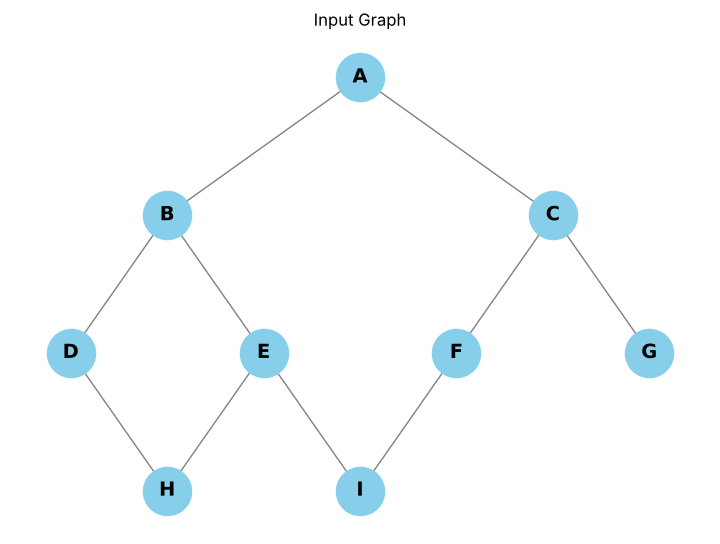

In [3]:
G = nx.Graph()
for node, neighbours in graph.items():
    for nb in neighbours:
        G.add_edge(node, nb)

pos = {'A': (0, 3), 'B': (-2, 2), 'C': (2, 2), 'D': (-3, 1), 'E': (-1, 1),
       'F': (1, 1), 'G': (3, 1), 'H': (-2, 0), 'I': (0, 0)}

plt.figure(figsize=(7, 5))
nx.draw(G, pos, with_labels=True, node_color='skyblue', node_size=1200,
        font_size=14, font_weight='bold', edge_color='gray')
plt.title('Input Graph')
plt.show()

## 4. Implement Breadth-First Search (BFS)
BFS explores the graph **level by level** using a **FIFO queue**. A node is marked visited when it is added to the queue so it is never enqueued twice.

**Algorithm:**
1. Put the start node in the queue and mark it visited.
2. Remove the front node from the queue and process it.
3. Add all of its unvisited neighbours to the back of the queue and mark them visited.
4. Repeat until the queue is empty.

In [4]:
def bfs(graph, start):
    visited = {start}
    queue = deque([start])
    order = []

    while queue:
        node = queue.popleft()
        order.append(node)
        for neighbour in graph[node]:
            if neighbour not in visited:
                visited.add(neighbour)
                queue.append(neighbour)
    return order

bfs_order = bfs(graph, 'A')
print("BFS traversal starting from A:", ' -> '.join(bfs_order))

BFS traversal starting from A: A -> B -> C -> D -> E -> F -> G -> H -> I


## 5. Trace the BFS queue step by step

In [5]:
def bfs_trace(graph, start):
    visited = {start}
    queue = deque([start])
    steps = []
    while queue:
        node = queue.popleft()
        added = []
        for neighbour in graph[node]:
            if neighbour not in visited:
                visited.add(neighbour)
                queue.append(neighbour)
                added.append(neighbour)
        steps.append({'Visited node': node, 'Neighbours added': added, 'Queue after step': list(queue)})
    return pd.DataFrame(steps)

display(bfs_trace(graph, 'A'))

,Visited node,Neighbours added,Queue after step
0,A,"[B, C]","[B, C]"
1,B,"[D, E]","[C, D, E]"
2,C,"[F, G]","[D, E, F, G]"
3,D,[H],"[E, F, G, H]"
4,E,[I],"[F, G, H, I]"
5,F,[],"[G, H, I]"
6,G,[],"[H, I]"
7,H,[],[I]
8,I,[],[]


## 6. BFS path finding (shortest path in terms of number of edges)
By remembering the **parent** of each node, BFS can reconstruct the path to a goal. Because BFS explores level by level, the first path found always uses the **fewest edges**.

In [6]:
def bfs_path(graph, start, goal):
    parent = {start: None}
    queue = deque([start])
    while queue:
        node = queue.popleft()
        if node == goal:
            path = []
            while node is not None:
                path.append(node)
                node = parent[node]
            return path[::-1]
        for neighbour in graph[node]:
            if neighbour not in parent:
                parent[neighbour] = node
                queue.append(neighbour)
    return None

path = bfs_path(graph, 'A', 'I')
print("BFS path from A to I:", ' -> '.join(path))
print("Number of edges:", len(path) - 1)

BFS path from A to I: A -> B -> E -> I
Number of edges: 3


## 7. Implement Depth-First Search (DFS) — iterative version
DFS goes **as deep as possible** along one branch before backtracking. The iterative version uses a **LIFO stack**. Neighbours are pushed in reverse order so that they are explored in alphabetical (left-to-right) order.

In [7]:
def dfs_iterative(graph, start):
    visited = set()
    stack = [start]
    order = []

    while stack:
        node = stack.pop()
        if node not in visited:
            visited.add(node)
            order.append(node)
            for neighbour in reversed(graph[node]):
                if neighbour not in visited:
                    stack.append(neighbour)
    return order

dfs_order = dfs_iterative(graph, 'A')
print("DFS (iterative) traversal starting from A:", ' -> '.join(dfs_order))

DFS (iterative) traversal starting from A: A -> B -> D -> H -> E -> I -> F -> C -> G


## 8. Implement Depth-First Search (DFS) — recursive version
The recursive version uses the **function call stack** instead of an explicit stack.

In [8]:
def dfs_recursive(graph, node, visited=None, order=None):
    if visited is None:
        visited, order = set(), []
    visited.add(node)
    order.append(node)
    for neighbour in graph[node]:
        if neighbour not in visited:
            dfs_recursive(graph, neighbour, visited, order)
    return order

dfs_rec_order = dfs_recursive(graph, 'A')
print("DFS (recursive) traversal starting from A:", ' -> '.join(dfs_rec_order))
print("Iterative and recursive DFS give the same order:", dfs_order == dfs_rec_order)

DFS (recursive) traversal starting from A: A -> B -> D -> H -> E -> I -> F -> C -> G
Iterative and recursive DFS give the same order: True


## 9. DFS path finding
DFS also finds a path to the goal, but it is **not guaranteed to be the shortest**.

In [9]:
def dfs_path(graph, start, goal, visited=None):
    if visited is None:
        visited = set()
    visited.add(start)
    if start == goal:
        return [start]
    for neighbour in graph[start]:
        if neighbour not in visited:
            sub_path = dfs_path(graph, neighbour, goal, visited)
            if sub_path:
                return [start] + sub_path
    return None

path_dfs = dfs_path(graph, 'A', 'I')
print("DFS path from A to I:", ' -> '.join(path_dfs))
print("Number of edges:", len(path_dfs) - 1)

DFS path from A to I: A -> B -> D -> H -> E -> I
Number of edges: 5


## 10. Visualize the BFS and DFS traversal order
The number on each node shows the order in which it was visited.

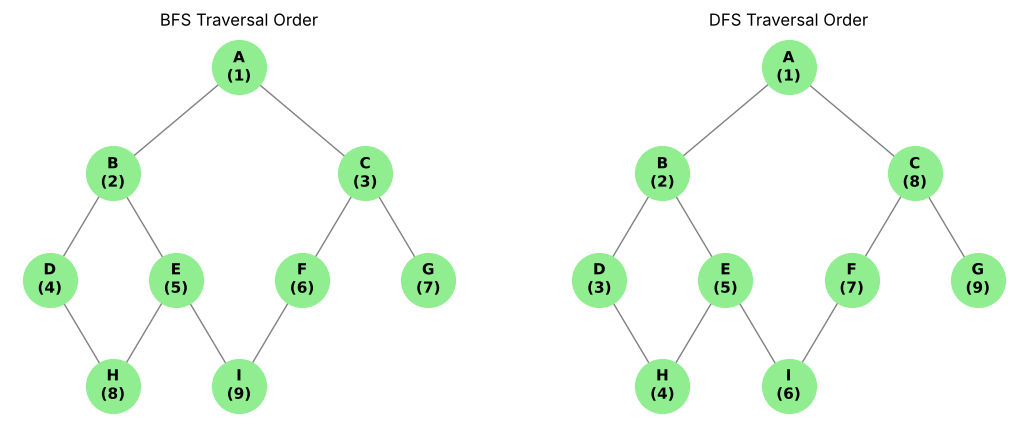

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, order, title in [(axes[0], bfs_order, 'BFS Traversal Order'),
                         (axes[1], dfs_order, 'DFS Traversal Order')]:
    labels = {n: f"{n}\n({order.index(n) + 1})" for n in order}
    nx.draw(G, pos, ax=ax, labels=labels, node_color='lightgreen', node_size=1500,
            font_size=11, font_weight='bold', edge_color='gray')
    ax.set_title(title)
plt.show()

## 11. Compare BFS and DFS

In [11]:
comparison = pd.DataFrame({
    'Traversal order': [' -> '.join(bfs_order), ' -> '.join(dfs_order)],
    'Path A to I': [' -> '.join(path), ' -> '.join(path_dfs)],
    'Path length (edges)': [len(path) - 1, len(path_dfs) - 1],
}, index=['BFS', 'DFS'])
display(comparison)

,Traversal order,Path A to I,Path length (edges)
BFS,A -> B -> C -> D -> E -> F -> G -> H -> I,A -> B -> E -> I,3
DFS,A -> B -> D -> H -> E -> I -> F -> C -> G,A -> B -> D -> H -> E -> I,5


| Property | BFS | DFS |
|---|---|---|
| Data structure | Queue (FIFO) | Stack (LIFO) / recursion |
| Exploration | Level by level | Deep along one branch, then backtrack |
| Complete? | Yes (finite branching factor) | Yes for finite graphs (with visited set) |
| Optimal? | Yes, for unweighted graphs (fewest edges) | No |
| Time complexity | O(V + E) | O(V + E) |
| Space complexity | O(b^d) — stores a whole level | O(b·m) — stores one path |

where *b* = branching factor, *d* = depth of the shallowest goal, *m* = maximum depth.

## 12. Application: solving a maze with BFS and DFS
The maze is a grid where `0` is an open cell and `1` is a wall. Each open cell is a node connected to its open neighbours (up, down, left, right). We search from the top-left corner to the bottom-right corner.

In [12]:
maze = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 1, 0],
    [0, 1, 0, 0, 0, 0, 0, 0],
    [0, 1, 0, 1, 1, 1, 1, 1],
    [0, 1, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
])
start, goal = (0, 0), (7, 7)
moves = [(0, 1), (1, 0), (0, -1), (-1, 0)]  # right, down, left, up

def neighbours(cell):
    r, c = cell
    for dr, dc in moves:
        nr, nc = r + dr, c + dc
        if 0 <= nr < maze.shape[0] and 0 <= nc < maze.shape[1] and maze[nr, nc] == 0:
            yield (nr, nc)

def maze_bfs(start, goal):
    parent, queue, explored = {start: None}, deque([start]), 0
    while queue:
        cell = queue.popleft()
        explored += 1
        if cell == goal:
            break
        for nb in neighbours(cell):
            if nb not in parent:
                parent[nb] = cell
                queue.append(nb)
    path, cell = [], goal
    while cell is not None:
        path.append(cell)
        cell = parent[cell]
    return path[::-1], explored

def maze_dfs(start, goal):
    parent, stack, visited, explored = {start: None}, [start], set(), 0
    while stack:
        cell = stack.pop()
        if cell in visited:
            continue
        visited.add(cell)
        explored += 1
        if cell == goal:
            break
        for nb in reversed(list(neighbours(cell))):
            if nb not in visited:
                parent[nb] = cell
                stack.append(nb)
    path, cell = [], goal
    while cell is not None:
        path.append(cell)
        cell = parent[cell]
    return path[::-1], explored

bfs_maze_path, bfs_explored = maze_bfs(start, goal)
dfs_maze_path, dfs_explored = maze_dfs(start, goal)
print(f"BFS: path length = {len(bfs_maze_path) - 1} steps, cells explored = {bfs_explored}")
print(f"DFS: path length = {len(dfs_maze_path) - 1} steps, cells explored = {dfs_explored}")

BFS: path length = 14 steps, cells explored = 29
DFS: path length = 24 steps, cells explored = 25


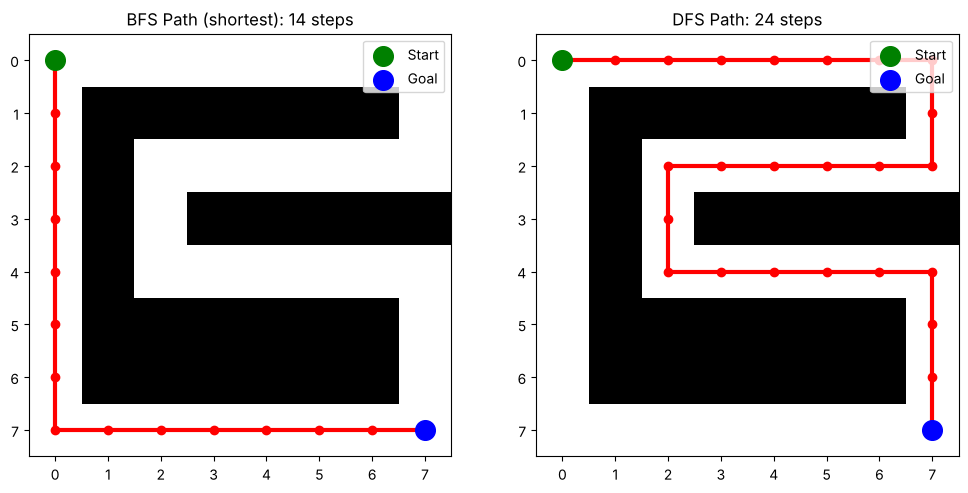

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, p, title in [(axes[0], bfs_maze_path, 'BFS Path (shortest)'),
                     (axes[1], dfs_maze_path, 'DFS Path')]:
    ax.imshow(maze, cmap='Greys')
    rows, cols = zip(*p)
    ax.plot(cols, rows, color='red', linewidth=3, marker='o')
    ax.scatter([start[1]], [start[0]], color='green', s=200, zorder=3, label='Start')
    ax.scatter([goal[1]], [goal[0]], color='blue', s=200, zorder=3, label='Goal')
    ax.set_title(f"{title}: {len(p) - 1} steps")
    ax.legend(loc='upper right')
plt.show()

**Interpretation:** BFS always returns the path with the fewest steps because it explores all cells at distance *k* before any cell at distance *k + 1*. DFS commits to the first direction it tries (right) and follows the long winding corridor, so it returns a much longer path. DFS only has to remember the current branch, so it usually needs less memory than BFS.

## 13. Documentation summary
1. Imported the libraries and represented the graph as an adjacency list
2. Visualized the graph using NetworkX
3. Implemented BFS using a queue and traced the queue at every step
4. Used BFS with parent tracking to find the shortest path (fewest edges)
5. Implemented DFS both iteratively (stack) and recursively
6. Used DFS to find a path between two nodes
7. Visualized and compared the traversal orders and paths of BFS and DFS
8. Applied BFS and DFS to solve a grid maze and compared path lengths and cells explored

**Result:** BFS and DFS were implemented successfully. Both traverse every reachable node in O(V + E) time; BFS gives the shortest path in an unweighted graph, while DFS explores deeply and may return a longer path.